# Section C — Mini Capstone Project
## Option 1: Load & Clean Data

This option loads a simulated food delivery dataset and performs data cleaning.

The cleaning process includes:
- Handling missing values
- Removing duplicate rows
- Detecting order_value outliers using the IQR method
- Capping outliers
- Displaying before-and-after data quality summaries

In [1]:
# Import required libraries
import pandas as pd
import numpy as np

In [2]:
# Create a simulated food delivery dataset

data = {
    'order_id': range(1001, 1021),

    'customer_name': [
        'Rahul', 'Amit', 'Priya', 'Neha', 'Rohan',
        'Karan', 'Anjali', 'Vikas', 'Pooja', 'Arjun',
        'Mehul', 'Sneha', 'Yash', 'Riya', 'Akash',
        'Nisha', 'Jay', 'Kavya', 'Dev', 'Isha'
    ],

    'restaurant_name': [
        'Spice Hub', 'Pizza House', 'China Bowl', 'Food Corner',
        'Royal Dine', 'Spice Hub', 'Pizza House', 'Burger Point',
        'China Bowl', 'Royal Dine', 'Spice Hub', 'Pizza House',
        'Food Corner', 'Burger Point', 'China Bowl', 'Royal Dine',
        'Spice Hub', 'Pizza House', 'Food Corner', 'Burger Point'
    ],

    'category': [
        'Indian', 'Italian', 'Chinese', 'Fast Food', 'Indian',
        'Indian', 'Italian', 'Fast Food', 'Chinese', 'Indian',
        'Indian', 'Italian', 'Fast Food', 'Fast Food', 'Chinese',
        'Indian', 'Indian', 'Italian', 'Fast Food', 'Fast Food'
    ],

    'delivery_time_mins': [
        30, 40, 35, 25, 45,
        32, 38, 28, 42, 36,
        31, 44, 27, 33, 41,
        39, 29, 46, 34, 37
    ],

    'order_value': [
        350, 500, 450, 300, 700,
        400, 550, 250, 600, 480,
        320, 520, 280, 390, 650,
        750, 360, 580, 310, 430
    ],

    'rating': [
        4.5, 4.0, 3.8, 4.2, 4.7,
        4.1, 3.9, 4.3, 4.0, 4.6,
        4.4, 3.7, 4.2, 4.1, 3.9,
        4.8, 4.3, 4.0, 4.5, 4.2
    ]
}

# Create DataFrame
df_capstone = pd.DataFrame(data)

# Manually introduce missing values
df_capstone.loc[2, 'delivery_time_mins'] = np.nan
df_capstone.loc[5, 'order_value'] = np.nan
df_capstone.loc[8, 'rating'] = np.nan
df_capstone.loc[11, 'category'] = np.nan

# Add 3 duplicate rows
df_capstone = pd.concat(
    [df_capstone, df_capstone.iloc[[0, 1, 2]]],
    ignore_index=True
)

# Add an extreme value to demonstrate outlier detection
df_capstone.loc[19, 'order_value'] = 5000

# Display the simulated data
df_capstone.head()

,order_id,customer_name,restaurant_name,category,delivery_time_mins,order_value,rating
0,1001,Rahul,Spice Hub,Indian,30.0,350.0,4.5
1,1002,Amit,Pizza House,Italian,40.0,500.0,4.0
2,1003,Priya,China Bowl,Chinese,NaN,450.0,3.8
3,1004,Neha,Food Corner,Fast Food,25.0,300.0,4.2
4,1005,Rohan,Royal Dine,Indian,45.0,700.0,4.7


In [3]:
# Print data quality summary BEFORE cleaning

print("========== BEFORE CLEANING ==========")

print("Number of rows:", len(df_capstone))
print("Number of columns:", len(df_capstone.columns))

print("\nMissing values:")
print(df_capstone.isnull().sum())

print("\nNumber of duplicate rows:", df_capstone.duplicated().sum())

print("\nOrder value statistics:")
print(df_capstone['order_value'].describe())

========== BEFORE CLEANING ==========
Number of rows: 23
Number of columns: 7

Missing values:
order_id              0
customer_name         0
restaurant_name       0
category              1
delivery_time_mins    2
order_value           1
rating                1
dtype: int64

Number of duplicate rows: 3

Order value statistics:
count      22.000000
mean      665.454545
std       978.179686
min       250.000000
25%       350.000000
50%       465.000000
75%       572.500000
max      5000.000000
Name: order_value, dtype: float64


In [4]:
# ---------------------------------------------------------
# Handle missing values
# ---------------------------------------------------------

# Fill delivery time with median
df_capstone['delivery_time_mins'] = df_capstone[
    'delivery_time_mins'
].fillna(
    df_capstone['delivery_time_mins'].median()
)

# Fill order value with median
df_capstone['order_value'] = df_capstone[
    'order_value'
].fillna(
    df_capstone['order_value'].median()
)

# Fill rating with mean rounded to 1 decimal
rating_mean = round(df_capstone['rating'].mean(), 1)

df_capstone['rating'] = df_capstone['rating'].fillna(
    rating_mean
)

# Fill category with mode
category_mode = df_capstone['category'].mode()[0]

df_capstone['category'] = df_capstone['category'].fillna(
    category_mode
)

print("Missing values handled successfully.")

Missing values handled successfully.


In [5]:
# Count duplicate rows before removing them
duplicates_before = df_capstone.duplicated().sum()

# Remove duplicate rows
df_capstone = df_capstone.drop_duplicates()

print("Duplicate rows removed:", duplicates_before)
print("Rows after removing duplicates:", len(df_capstone))

Duplicate rows removed: 3
Rows after removing duplicates: 20


In [6]:
# ---------------------------------------------------------
# Detect outliers using IQR method
# ---------------------------------------------------------

# Calculate Q1 and Q3
Q1 = df_capstone['order_value'].quantile(0.25)
Q3 = df_capstone['order_value'].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate outlier limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Find outlier rows
outliers = df_capstone[
    (df_capstone['order_value'] < lower_limit) |
    (df_capstone['order_value'] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("\nLower limit:", lower_limit)
print("Upper limit:", upper_limit)

print("\nOutlier rows:")
print(outliers[['order_id', 'order_value']])

# Cap order_value using the upper and lower limits
df_capstone['order_value'] = df_capstone[
    'order_value'
].clip(
    lower=lower_limit,
    upper=upper_limit
)

print("\nOutliers capped successfully.")

Q1: 342.5
Q3: 585.0
IQR: 242.5

Lower limit: -21.25
Upper limit: 948.75

Outlier rows:
    order_id  order_value
19      1020       5000.0

Outliers capped successfully.


In [7]:
# Print data quality summary AFTER cleaning

print("========== AFTER CLEANING ==========")

print("Number of rows:", len(df_capstone))
print("Number of columns:", len(df_capstone.columns))

print("\nMissing values:")
print(df_capstone.isnull().sum())

print("\nNumber of duplicate rows:", df_capstone.duplicated().sum())

print("\nOrder value statistics:")
print(df_capstone['order_value'].describe())

========== AFTER CLEANING ==========
Number of rows: 20
Number of columns: 7

Missing values:
order_id              0
customer_name         0
restaurant_name       0
category              0
delivery_time_mins    0
order_value           0
rating                0
dtype: int64

Number of duplicate rows: 0

Order value statistics:
count     20.000000
mean     487.687500
std      180.695966
min      250.000000
25%      342.500000
50%      472.500000
75%      585.000000
max      948.750000
Name: order_value, dtype: float64


In [8]:
# Display the final cleaned DataFrame

df_capstone

,order_id,customer_name,restaurant_name,category,delivery_time_mins,order_value,rating
0,1001,Rahul,Spice Hub,Indian,30.0,350.00,4.5
1,1002,Amit,Pizza House,Italian,40.0,500.00,4.0
2,1003,Priya,China Bowl,Chinese,36.0,450.00,3.8
3,1004,Neha,Food Corner,Fast Food,25.0,300.00,4.2
4,1005,Rohan,Royal Dine,Indian,45.0,700.00,4.7
5,1006,Karan,Spice Hub,Indian,32.0,465.00,4.1
6,1007,Anjali,Pizza House,Italian,38.0,550.00,3.9
7,1008,Vikas,Burger Point,Fast Food,28.0,250.00,4.3
8,1009,Pooja,China Bowl,Chinese,42.0,600.00,4.2
9,1010,Arjun,Royal Dine,Indian,36.0,480.00,4.6


# Section C — Option 2: Run SQL Analysis

This option connects the cleaned food delivery data to a SQLite database.

Two SQL analyses are performed:

1. GROUP BY analysis using COUNT(), SUM(), and AVG()
2. JOIN analysis between restaurants and orders

The results are displayed as clean Pandas tables.

In [9]:
# Import SQLite
import sqlite3

# Connect to a SQLite database
conn = sqlite3.connect('food_delivery_capstone.db')

print("SQLite database connected successfully.")

SQLite database connected successfully.


In [10]:
# ---------------------------------------------------------
# Create restaurants table
# ---------------------------------------------------------

# Get unique restaurant information from the cleaned DataFrame
restaurants_df = df_capstone[
    ['restaurant_name', 'category']
].drop_duplicates().reset_index(drop=True)

# Create a restaurant_id
restaurants_df['restaurant_id'] = range(
    1,
    len(restaurants_df) + 1
)

# Rearrange columns
restaurants_df = restaurants_df[
    ['restaurant_id', 'restaurant_name', 'category']
]

# Save restaurants data into SQLite
restaurants_df.to_sql(
    'restaurants',
    conn,
    if_exists='replace',
    index=False
)


# ---------------------------------------------------------
# Create orders table
# ---------------------------------------------------------

# Create a copy of cleaned order data
orders_df = df_capstone.copy()

# Add restaurant_id by matching restaurant names
orders_df = orders_df.merge(
    restaurants_df[['restaurant_id', 'restaurant_name']],
    on='restaurant_name',
    how='left'
)

# Select columns required for SQL analysis
orders_df = orders_df[
    [
        'order_id',
        'restaurant_id',
        'order_value',
        'delivery_time_mins',
        'rating'
    ]
]

# Save orders data into SQLite
orders_df.to_sql(
    'orders',
    conn,
    if_exists='replace',
    index=False
)

print("Restaurants and orders tables created successfully.")

Restaurants and orders tables created successfully.


In [11]:
# ---------------------------------------------------------
# SQL Query 1
# GROUP BY with COUNT(), SUM(), and AVG()
# ---------------------------------------------------------

query_1 = """
SELECT
    r.category,
    COUNT(o.order_id) AS total_orders,
    SUM(o.order_value) AS total_revenue,
    ROUND(AVG(o.rating), 2) AS average_rating

FROM restaurants AS r

JOIN orders AS o
    ON r.restaurant_id = o.restaurant_id

GROUP BY r.category

ORDER BY total_revenue DESC;
"""

# Execute SQL query and load result into Pandas
groupby_result = pd.read_sql_query(
    query_1,
    conn
)

# Display result as a clean table
print("===== CATEGORY PERFORMANCE =====")
print(groupby_result.to_string(index=False))

===== CATEGORY PERFORMANCE =====
 category  total_orders  total_revenue  average_rating
   Indian            11        5575.00            4.27
Fast Food             6        2478.75            4.25
  Italian             4        2150.00            3.90
  Chinese             3        1700.00            3.97


In [12]:
# ---------------------------------------------------------
# SQL Query 2
# JOIN restaurants and orders
# ---------------------------------------------------------

query_2 = """
SELECT
    o.order_id,
    r.restaurant_name,
    r.category,
    o.order_value,
    o.delivery_time_mins,
    o.rating

FROM orders AS o

JOIN restaurants AS r
    ON o.restaurant_id = r.restaurant_id

ORDER BY o.order_id;
"""

# Execute SQL query and load result into Pandas
join_result = pd.read_sql_query(
    query_2,
    conn
)

# Display result as a clean table
print("===== ORDER DETAILS WITH RESTAURANT INFORMATION =====")
print(join_result.to_string(index=False))

===== ORDER DETAILS WITH RESTAURANT INFORMATION =====
 order_id restaurant_name  category  order_value  delivery_time_mins  rating
     1001       Spice Hub    Indian       350.00                30.0     4.5
     1002     Pizza House   Italian       500.00                40.0     4.0
     1002     Pizza House    Indian       500.00                40.0     4.0
     1003      China Bowl   Chinese       450.00                36.0     3.8
     1004     Food Corner Fast Food       300.00                25.0     4.2
     1005      Royal Dine    Indian       700.00                45.0     4.7
     1006       Spice Hub    Indian       465.00                32.0     4.1
     1007     Pizza House   Italian       550.00                38.0     3.9
     1007     Pizza House    Indian       550.00                38.0     3.9
     1008    Burger Point Fast Food       250.00                28.0     4.3
     1009      China Bowl   Chinese       600.00                42.0     4.2
     1010      Royal D

In [13]:
# Close the SQLite connection
conn.close()

print("SQLite database connection closed.")

SQLite database connection closed.


# Section C — Option 3: View Charts

This option creates two side-by-side visualizations using Matplotlib and Seaborn.

1. Countplot showing the number of orders by restaurant category.
2. Barplot showing the average delivery time by city.

Both charts include descriptive titles and axis labels.

In [17]:
# ---------------------------------------------------------
# Add city information to our cleaned DataFrame
# ---------------------------------------------------------

# Assign each restaurant to a city
restaurant_city = {
    'Spice Hub': 'Surat',
    'Pizza House': 'Surat',
    'China Bowl': 'Mumbai',
    'Food Corner': 'Surat',
    'Royal Dine': 'Ahmedabad',
    'Burger Point': 'Mumbai'
}

# Create a city column using restaurant name
df_capstone['city'] = df_capstone['restaurant_name'].map(
    restaurant_city
)

# Check the city column
print(df_capstone[['restaurant_name', 'city']].drop_duplicates())

  restaurant_name       city
0       Spice Hub      Surat
1     Pizza House      Surat
2      China Bowl     Mumbai
3     Food Corner      Surat
4      Royal Dine  Ahmedabad
7    Burger Point     Mumbai


In [18]:
# ---------------------------------------------------------
# Recreate restaurants table with city
# ---------------------------------------------------------

# Create restaurant information including city
restaurants_df = df_capstone[
    ['restaurant_name', 'category', 'city']
].drop_duplicates().reset_index(drop=True)

# Create restaurant IDs
restaurants_df['restaurant_id'] = range(
    1,
    len(restaurants_df) + 1
)

# Arrange columns
restaurants_df = restaurants_df[
    ['restaurant_id', 'restaurant_name', 'category', 'city']
]

# Replace the old restaurants table
restaurants_df.to_sql(
    'restaurants',
    conn,
    if_exists='replace',
    index=False
)


# ---------------------------------------------------------
# Recreate orders table
# ---------------------------------------------------------

orders_df = df_capstone.copy()

# Connect orders with restaurant IDs
orders_df = orders_df.merge(
    restaurants_df[['restaurant_id', 'restaurant_name']],
    on='restaurant_name',
    how='left'
)

# Keep required order columns
orders_df = orders_df[
    [
        'order_id',
        'restaurant_id',
        'order_value',
        'delivery_time_mins',
        'rating'
    ]
]

# Replace the old orders table
orders_df.to_sql(
    'orders',
    conn,
    if_exists='replace',
    index=False
)

print("SQLite tables updated successfully.")

SQLite tables updated successfully.


In [19]:
# Check the restaurants table structure

print("Restaurants table:")
print(
    pd.read_sql_query(
        "SELECT * FROM restaurants",
        conn
    )
)

Restaurants table:
   restaurant_id restaurant_name   category       city
0              1       Spice Hub     Indian      Surat
1              2     Pizza House    Italian      Surat
2              3      China Bowl    Chinese     Mumbai
3              4     Food Corner  Fast Food      Surat
4              5      Royal Dine     Indian  Ahmedabad
5              6    Burger Point  Fast Food     Mumbai
6              7     Pizza House     Indian      Surat


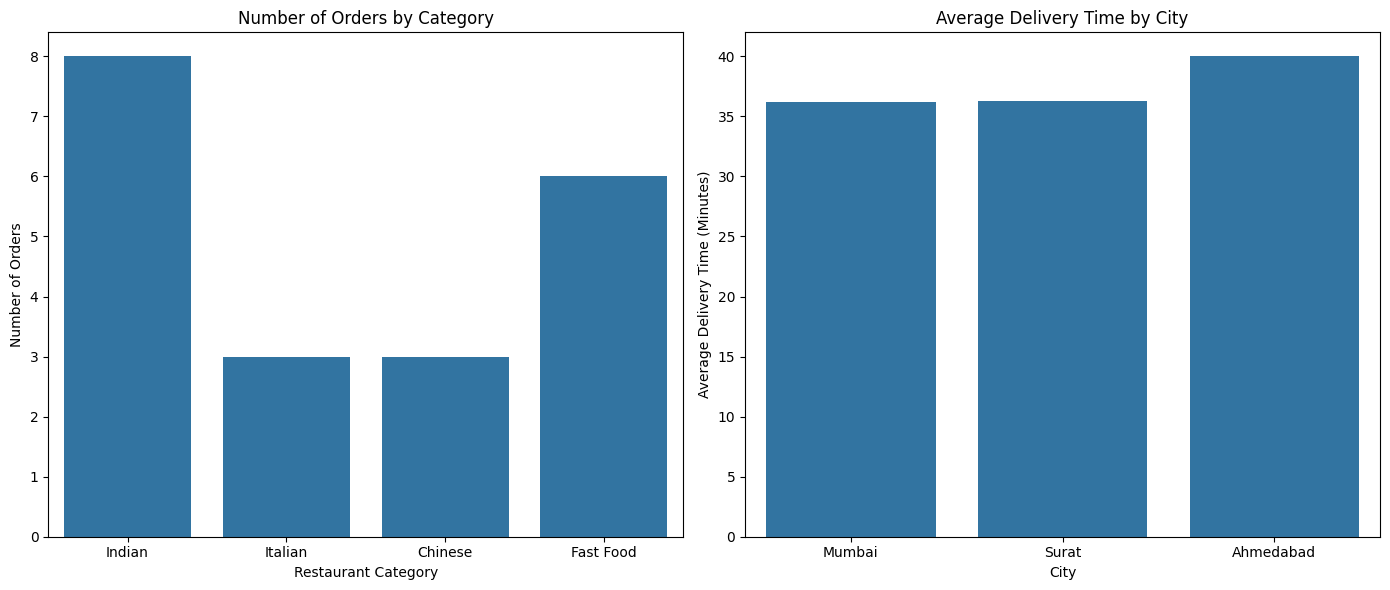

In [20]:
# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Create a 1 × 2 figure
fig, axes = plt.subplots(1, 2, figsize=(14, 6))


# ---------------------------------------------------------
# Chart 1: Orders by Category
# ---------------------------------------------------------

sns.countplot(
    data=df_capstone,
    x='category',
    ax=axes[0]
)

axes[0].set_title('Number of Orders by Category')
axes[0].set_xlabel('Restaurant Category')
axes[0].set_ylabel('Number of Orders')


# ---------------------------------------------------------
# Chart 2: Average Delivery Time by City
# ---------------------------------------------------------

# Calculate average delivery time for each city using SQL
city_delivery = pd.read_sql_query("""
    SELECT
        r.city,
        AVG(o.delivery_time_mins) AS average_delivery_time

    FROM restaurants AS r

    JOIN orders AS o
        ON r.restaurant_id = o.restaurant_id

    GROUP BY r.city

    ORDER BY average_delivery_time
""", conn)


# Create Seaborn barplot
sns.barplot(
    data=city_delivery,
    x='city',
    y='average_delivery_time',
    ax=axes[1]
)

axes[1].set_title('Average Delivery Time by City')
axes[1].set_xlabel('City')
axes[1].set_ylabel('Average Delivery Time (Minutes)')


# Adjust spacing
plt.tight_layout()

# Display charts
plt.show()

# Section C — Option 4: Export Report

This option exports the cleaned food delivery data and SQL analysis results into one Excel workbook.

The Excel file contains separate sheets for:
1. Cleaned Data
2. SQL Category Analysis
3. SQL Order Details

The file is created using Pandas ExcelWriter.

In [21]:
# Import os to verify the file path
import os

# Name of the Excel report
output_file = 'food_delivery_report.xlsx'


# ---------------------------------------------------------
# Create Excel workbook
# ---------------------------------------------------------

with pd.ExcelWriter(output_file, engine='openpyxl') as writer:

    # Sheet 1: Cleaned Data
    df_capstone.to_excel(
        writer,
        sheet_name='Cleaned Data',
        index=False
    )

    # Sheet 2: SQL GROUP BY result
    groupby_result.to_excel(
        writer,
        sheet_name='SQL Category Analysis',
        index=False
    )

    # Sheet 3: SQL JOIN result
    join_result.to_excel(
        writer,
        sheet_name='SQL Order Details',
        index=False
    )


# ---------------------------------------------------------
# Confirm file creation
# ---------------------------------------------------------

file_path = os.path.abspath(output_file)

print("Excel report exported successfully!")
print("File path:", file_path)
print("File exists:", os.path.exists(output_file))

Excel report exported successfully!
File path: C:\Users\admin\Desktop\Tops Technology\Data Science\Assignments\Assestment\2 Working with Databases\Section C — Mini Capstone Project\food_delivery_report.xlsx
File exists: True


In [22]:
# Verify that the Excel file contains the required sheets

excel_file = pd.ExcelFile('food_delivery_report.xlsx')

print("Excel file:", excel_file)
print("\nSheets in the report:")

for sheet in excel_file.sheet_names:
    print("-", sheet)

Excel file: <pandas.io.excel._base.ExcelFile object at 0x000001FBA4CC2120>

Sheets in the report:
- Cleaned Data
- SQL Category Analysis
- SQL Order Details
